In [1]:
from ufl import SpatialCoordinate, dot
from dune.grid import cartesianDomain
from dune.alugrid import aluConformGrid as leafGridView
from dune.fem.view import filteredGridView
from dune.fem.space import lagrange

In [2]:
gridView = leafGridView( cartesianDomain([0,0],[1,1],[16,16]) )

GridParameterBlock: Parameter 'refinementedge' not specified, 


Created parallel ALUGrid<2,2,simplex,conforming> from input stream. 



defaulting to 'ARBITRARY'.
WARNING (ignored): Could not open file 'alugrid.cfg', using default values 0 < [balance] < 1.2, partitioning method 'ALUGRID_SpaceFillingCurve(9)'.

You are using DUNE-ALUGrid, please don't forget to cite the paper:
Alkaemper, Dedner, Kloefkorn, Nolte. The DUNE-ALUGrid Module, 2016.


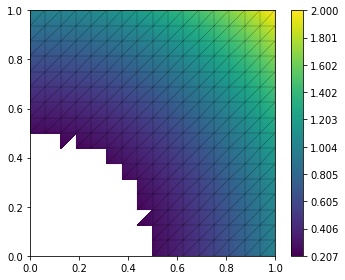

number of dofs: 1089 integral over filtered domain 0.6413014729817705


In [3]:
filteredView = filteredGridView(gridView, lambda e: e.geometry.center.two_norm > 0.5, domainId=1)
space = lagrange(filteredView, order=2)
x = SpatialCoordinate(space)
solution = space.interpolate(dot(x,x),name="solution")
solution.plot()
print("number of dofs:", solution.size,\
      "integral over filtered domain",solution.integrate())

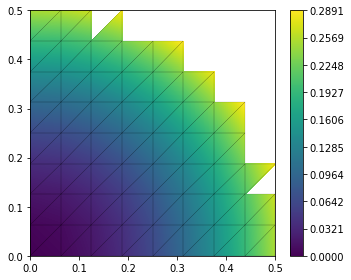

number of dofs: 239 integral over filtered domain 0.02536519368489583


In [4]:
filteredView = filteredGridView(gridView, lambda e: e.geometry.center.two_norm < 0.5, domainId=1,
                                useFilteredIndexSet=True)
space = lagrange(filteredView, order=2)
x = SpatialCoordinate(space)
solution = space.interpolate(dot(x,x),name="solution")
solution.plot()
print("number of dofs:", solution.size,\
      "integral over filtered domain",solution.integrate())

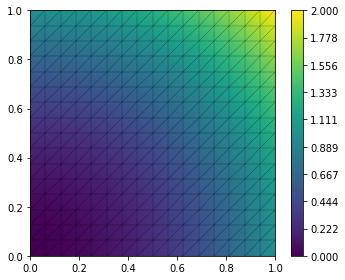

number of dofs: 1089 integral over filtered domain 0.6666666666666667


In [5]:
space = lagrange(gridView, order=2)
solution = space.interpolate(dot(x,x),name="solution")
solution.plot()
print("number of dofs:", solution.size,\
      "integral over filtered domain",solution.integrate())